In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
from pathlib import Path

root = Path('/content/drive/MyDrive')
print('My Drive available:', root.exists())

for item in sorted(root.iterdir()):
    print(item.name)

print('\nZIP files:')
for item in root.rglob('*'):
    if item.is_file() and item.suffix.lower() == '.zip':
        print(item)

My Drive available: True
123158859.pdf
1716129454954.jpg
1784967315 - 25000.00 To HARCOURT BUTLER TECHNICAL UNIVERSITY on Google Pay (1).png
1784967315 - 25000.00 To HARCOURT BUTLER TECHNICAL UNIVERSITY on Google Pay (2).png
1784967315 - 25000.00 To HARCOURT BUTLER TECHNICAL UNIVERSITY on Google Pay.png
2023071726.pdf
20250411_003505-COLLAGE.jpg
20250411_003648-COLLAGE.jpg
20250411_003818-COLLAGE.jpg
230108047_Prateekchaurasiya_IIIrd_IT (2).zip
406554_cert (1).pdf
406554_cert.pdf asus warenty .pdf
406554_receipt.pdf asus invoice .pdf
5U7A1796-1.JPG
AUD-20221005-WA0002 (1).mp3
AUD-20221005-WA0002.mp3
AUD-20221005-WA0003.mp3
AUD-20221005-WA0004.mp3
AUD-20221005-WA0005 (1).mp3
AUD-20221005-WA0005 (2).mp3
AUD-20221005-WA0005.mp3
AUD-20221005-WA0006.mp3
AUD-20221101-WA0004 (1).opus
AUD-20221101-WA0004 (2).opus
AUD-20221101-WA0004.opus
AdmitCard-230310486212.pdf
B2B Website Audit & Improvement Plan (1).gdoc
B2B Website Audit & Improvement Plan.gdoc
CUETAdmitCard-223510703307.pdf
Calm.ogg
Can

In [11]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
from google.colab import files
uploaded = files.upload()

Saving EcoSort_TrashNet_split.zip to EcoSort_TrashNet_split.zip


In [14]:
from pathlib import Path
import zipfile

assert len(uploaded) == 1, 'Expected one uploaded ZIP file'
zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name) as archive:
    archive.extractall('/content/ecosort_data')

data_dir = Path('/content/ecosort_data/split')
counts = {}

for split in ('train', 'val', 'test'):
    counts[split] = sum(
        f.is_file() and f.suffix.lower() in ('.jpg', '.jpeg', '.png')
        for f in (data_dir / split).rglob('*')
    )
    print(f'{split}: {counts[split]} images')

assert counts == {'train': 1766, 'val': 378, 'test': 383}, 'Unexpected image counts'
print('Dataset ready')


train: 1766 images
val: 378 images
test: 383 images
Dataset ready


In [15]:
import sys
import torch
import torchvision

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('GPU available:', torch.cuda.is_available())

if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [16]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)

class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(data_dir / 'train', train_transform)
val_dataset = datasets.ImageFolder(data_dir / 'val', eval_transform)
test_dataset = datasets.ImageFolder(data_dir / 'test', eval_transform)

for dataset in (train_dataset, val_dataset, test_dataset):
    assert dataset.classes == class_names, 'Class labels do not match'

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)

print('Classes:', train_dataset.class_to_idx)
print('Train:', len(train_dataset))
print('Validation:', len(val_dataset))
print('Test:', len(test_dataset))

images, labels = next(iter(train_loader))
print('Image batch shape:', images.shape)
print('Label batch shape:', labels.shape)

Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Train: 1766
Validation: 378
Test: 383
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


In [17]:
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = resnet18(weights=ResNet18_Weights.DEFAULT)

# First, train only the new classification layer.
for parameter in model.parameters():
    parameter.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

class_counts = torch.bincount(
    torch.tensor(train_dataset.targets),
    minlength=len(class_names)
)
class_weights = len(train_dataset) / (len(class_names) * class_counts.float())

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

print('Model ready: ResNet18')
print('Device:', device)
print('Output classes:', model.fc.out_features)
print('Training images per class:', class_counts.tolist())

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 91.8MB/s]


Model ready: ResNet18
Device: cuda
Output classes: 6
Training images per class: [282, 350, 287, 415, 337, 95]


In [18]:
best_val_accuracy = -1.0
checkpoint_path = '/content/ecosort_resnet18_best.pth'
history = []

for epoch in range(1, 11):
    # Keep the frozen image-recognition layers unchanged.
    model.eval()
    model.fc.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_accuracy = train_correct / train_total
    val_accuracy = val_correct / val_total
    history.append({
        'epoch': epoch,
        'train_accuracy': train_accuracy,
        'val_accuracy': val_accuracy
    })

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save({
            'model_state_dict': {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            'class_names': class_names,
            'architecture': 'resnet18',
            'image_size': 224,
            'normalize_mean': [0.485, 0.456, 0.406],
            'normalize_std': [0.229, 0.224, 0.225],
            'epoch': epoch,
            'val_accuracy': val_accuracy
        }, checkpoint_path)

    print(
        f'Epoch {epoch}/10 | '
        f'Train: {train_accuracy:.1%} | '
        f'Validation: {val_accuracy:.1%}',
        flush=True
    )

print(f'Finished. Best validation accuracy: {best_val_accuracy:.1%}')
print('Saved:', checkpoint_path)

Epoch 1/10 | Train: 47.1% | Validation: 65.6%
Epoch 2/10 | Train: 67.5% | Validation: 75.1%
Epoch 3/10 | Train: 73.6% | Validation: 74.6%
Epoch 4/10 | Train: 77.4% | Validation: 74.3%
Epoch 5/10 | Train: 77.7% | Validation: 78.0%
Epoch 6/10 | Train: 79.8% | Validation: 81.0%
Epoch 7/10 | Train: 80.9% | Validation: 80.4%
Epoch 8/10 | Train: 81.4% | Validation: 79.9%
Epoch 9/10 | Train: 80.8% | Validation: 80.4%
Epoch 10/10 | Train: 81.2% | Validation: 79.9%
Finished. Best validation accuracy: 81.0%
Saved: /content/ecosort_resnet18_best.pth


In [19]:
from google.colab import files
files.download('/content/ecosort_resnet18_best.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from sklearn.metrics import accuracy_score, classification_report

checkpoint = torch.load(
    '/content/ecosort_resnet18_best.pth',
    map_location='cpu',
    weights_only=True
)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

actual_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predicted_labels.extend(outputs.argmax(1).cpu().tolist())
        actual_labels.extend(labels.tolist())

print('Saved model epoch:', checkpoint['epoch'])
print(f'Test accuracy: {accuracy_score(actual_labels, predicted_labels):.1%}')
print()
print(classification_report(
    actual_labels,
    predicted_labels,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=3,
    zero_division=0
))

Saved model epoch: 6
Test accuracy: 78.9%

              precision    recall  f1-score   support

   cardboard      0.927     0.836     0.879        61
       glass      0.714     0.724     0.719        76
       metal      0.713     0.919     0.803        62
       paper      0.854     0.778     0.814        90
     plastic      0.836     0.767     0.800        73
       trash      0.591     0.619     0.605        21

    accuracy                          0.789       383
   macro avg      0.772     0.774     0.770       383
weighted avg      0.797     0.789     0.790       383



In [21]:
from pathlib import Path
from google.colab import files

report = classification_report(
    actual_labels,
    predicted_labels,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=3,
    zero_division=0
)

result_path = Path('/content/EcoSort_TrashNet_Test_Results.txt')
result_path.write_text(
    f"Model: ResNet18\n"
    f"Best epoch: {checkpoint['epoch']}\n"
    f"Validation accuracy: {checkpoint['val_accuracy']:.1%}\n"
    f"Test accuracy: {accuracy_score(actual_labels, predicted_labels):.1%}\n\n"
    + report,
    encoding='utf-8'
)

files.download(str(result_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving images (12).jpeg to images (12) (3).jpeg


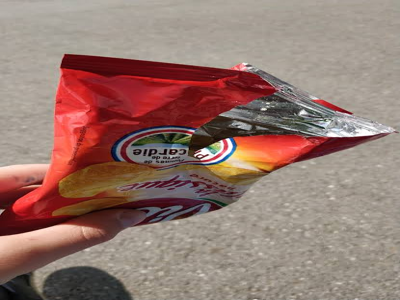

Prediction: trash
Model score: 81.8%


In [77]:
from google.colab import files
from PIL import Image
import io

photo_upload = files.upload()
assert len(photo_upload) == 1, 'Please upload one photo'

photo_name = next(iter(photo_upload))
photo = Image.open(io.BytesIO(photo_upload[photo_name])).convert('RGB')

model.eval()
image_tensor = eval_transform(photo).unsqueeze(0).to(device)

with torch.no_grad():
    probabilities = model(image_tensor).softmax(dim=1)[0]

predicted_index = probabilities.argmax().item()

display(photo.resize((400, 300)))
print('Prediction:', class_names[predicted_index])
print(f'Model score: {probabilities[predicted_index].item():.1%}')

In [78]:
for index in probabilities.argsort(descending=True).tolist():
    print(f'{class_names[index]}: {probabilities[index].item():.1%}')

trash: 81.8%
metal: 16.2%
cardboard: 1.2%
paper: 0.5%
plastic: 0.2%
glass: 0.0%


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

examples = sorted((data_dir / 'train' / 'trash').glob('*.jpg'))[:6]

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, path in zip(axes.flat, examples):
    with Image.open(path) as image:
        ax.imshow(image)
    ax.set_title(path.name)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [50]:
# Start from the saved best model.
model.load_state_dict(checkpoint['model_state_dict'])

# Allow the last image-recognition block and classifier to learn.
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True

optimizer = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 0.00001},
    {'params': model.fc.parameters(), 'lr': 0.0001}
])

print('Fine-tuning setup ready. Training has not started.')

Fine-tuning setup ready. Training has not started.


In [51]:
fine_tune_path = '/content/ecosort_resnet18_finetuned.pth'
best_fine_val = checkpoint['val_accuracy']

# Save the starting model in case fine-tuning doesn't improve it.
torch.save(checkpoint, fine_tune_path)

for epoch in range(1, 11):
    model.eval()
    model.layer4.train()
    model.fc.train()

    # Keep batch-normalization statistics fixed.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_accuracy = train_correct / train_total
    val_accuracy = val_correct / val_total

    if val_accuracy > best_fine_val:
        best_fine_val = val_accuracy
        improved_checkpoint = {
            **checkpoint,
            'model_state_dict': {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            },
            'stage': 'fine_tuning',
            'epoch': epoch,
            'val_accuracy': val_accuracy
        }
        torch.save(improved_checkpoint, fine_tune_path)

    print(
        f'Epoch {epoch}/10 | Train: {train_accuracy:.1%} | '
        f'Validation: {val_accuracy:.1%}',
        flush=True
    )

print(f'Best saved validation accuracy: {best_fine_val:.1%}')

best_checkpoint = torch.load(
    fine_tune_path, map_location='cpu', weights_only=True
)
model.load_state_dict(best_checkpoint['model_state_dict'])
model.to(device)
model.eval()
print('Best saved model loaded for predictions.')

Epoch 1/10 | Train: 81.7% | Validation: 79.9%
Epoch 2/10 | Train: 84.8% | Validation: 82.8%
Epoch 3/10 | Train: 87.0% | Validation: 80.7%
Epoch 4/10 | Train: 88.0% | Validation: 85.2%
Epoch 5/10 | Train: 90.2% | Validation: 83.3%
Epoch 6/10 | Train: 91.7% | Validation: 85.7%
Epoch 7/10 | Train: 92.9% | Validation: 85.2%
Epoch 8/10 | Train: 93.7% | Validation: 84.7%
Epoch 9/10 | Train: 94.3% | Validation: 86.8%
Epoch 10/10 | Train: 94.2% | Validation: 87.3%
Best saved validation accuracy: 87.3%
Best saved model loaded for predictions.


In [52]:
from google.colab import files
files.download('/content/ecosort_resnet18_finetuned.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
val_actual = []
val_predicted = []

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images.to(device))
        val_predicted.extend(outputs.argmax(1).cpu().tolist())
        val_actual.extend(labels.tolist())

print(classification_report(
    val_actual,
    val_predicted,
    labels=list(range(6)),
    target_names=class_names,
    digits=3,
    zero_division=0
))

matrix = confusion_matrix(val_actual, val_predicted, labels=list(range(6)))
print('Actual trash images predicted as:')
for name, count in zip(class_names, matrix[5]):
    print(f'{name}: {count}')

              precision    recall  f1-score   support

   cardboard      0.964     0.900     0.931        60
       glass      0.938     0.813     0.871        75
       metal      0.917     0.902     0.909        61
       paper      0.907     0.876     0.891        89
     plastic      0.776     0.917     0.841        72
       trash      0.615     0.762     0.681        21

    accuracy                          0.873       378
   macro avg      0.853     0.862     0.854       378
weighted avg      0.883     0.873     0.875       378

Actual trash images predicted as:
cardboard: 0
glass: 1
metal: 0
paper: 3
plastic: 1
trash: 16


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

trash_examples = [
    (path, prediction)
    for (path, label), prediction
    in zip(val_dataset.samples, val_predicted)
    if label == class_names.index('trash')
]

fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for ax in axes.flat:
    ax.axis('off')

for ax, (path, prediction) in zip(axes.flat, trash_examples):
    with Image.open(path) as image:
        ax.imshow(image)
    ax.set_title(
        f'{Path(path).name}\nPredicted: {class_names[prediction]}',
        color='green' if class_names[prediction] == 'trash' else 'red',
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [63]:
from google.colab import files
wrapper_upload = files.upload()

Saving images (10).jpeg to images (10) (2).jpeg
Saving images (11).jpeg to images (11) (2).jpeg
Saving images (12).jpeg to images (12) (2).jpeg
Saving images (13).jpeg to images (13) (3).jpeg
Saving images (14).jpeg to images (14).jpeg
Saving images (15).jpeg to images (15).jpeg
Saving images (16).jpeg to images (16).jpeg
Saving images (17).jpeg to images (17).jpeg
Saving images (18).jpeg to images (18).jpeg
Saving images (19).jpeg to images (19).jpeg


In [ ]:
import io
import matplotlib.pyplot as plt
from PIL import Image

assert len(wrapper_upload) == 10, 'Expected 10 images'

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, (name, content) in zip(axes.flat, sorted(wrapper_upload.items())):
    with Image.open(io.BytesIO(content)) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(name, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [66]:
from pathlib import Path
from PIL import Image, ImageOps
import io
import re

extra_dir = Path('/content/ecosort_extra/train/trash')
extra_dir.mkdir(parents=True, exist_ok=True)

saved = 0
for name, content in wrapper_upload.items():
    match = re.search(r'images \((\d+)\)', name)
    assert match, f'Unexpected filename: {name}'
    number = int(match.group(1))

    if number in (11, 15):
        print('Excluded:', name)
        continue

    with Image.open(io.BytesIO(content)) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        image.save(extra_dir / f'extra_wrapper_{number}.jpg', quality=95)

    saved += 1

print('Supplemental training images saved:', saved)
print('Original TrashNet split unchanged.')

Excluded: images (11) (2).jpeg
Excluded: images (15).jpeg
Supplemental training images saved: 8
Original TrashNet split unchanged.


In [67]:
from torch.utils.data import Dataset, ConcatDataset, DataLoader
from PIL import Image

class WrapperDataset(Dataset):
    def __init__(self, folder, transform):
        self.paths = sorted(Path(folder).glob('*.jpg'))
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = self.transform(image.convert('RGB'))
        return image, class_names.index('trash')

extra_dataset = WrapperDataset(extra_dir, train_transform)
assert len(extra_dataset) == 8, 'Expected eight supplemental images'

combined_dataset = ConcatDataset([train_dataset, extra_dataset])
combined_loader = DataLoader(
    combined_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print('Original training images:', len(train_dataset))
print('Added wrapper images:', len(extra_dataset))
print('Combined training images:', len(combined_dataset))
print('Extra image label:', extra_dataset[0][1])
print('Validation and test datasets unchanged.')

Original training images: 1766
Added wrapper images: 8
Combined training images: 1774
Extra image label: 5
Validation and test datasets unchanged.


In [68]:
starting_checkpoint = torch.load(
    fine_tune_path, map_location='cpu', weights_only=True
)
model.load_state_dict(starting_checkpoint['model_state_dict'])
model.to(device)

updated_counts = class_counts.clone()
updated_counts[5] += len(extra_dataset)
updated_weights = len(combined_dataset) / (6 * updated_counts.float())
criterion = nn.CrossEntropyLoss(weight=updated_weights.to(device))

optimizer = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 0.00001},
    {'params': model.fc.parameters(), 'lr': 0.0001}
])

wrapper_model_path = '/content/ecosort_resnet18_wrappers.pth'
best_wrapper_val = starting_checkpoint['val_accuracy']
torch.save(starting_checkpoint, wrapper_model_path)

for epoch in range(1, 6):
    model.eval()
    model.layer4.train()
    model.fc.train()

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    for images, labels in combined_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images.to(device))
            correct += (outputs.argmax(1).cpu() == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total

    if val_accuracy > best_wrapper_val:
        best_wrapper_val = val_accuracy
        torch.save({
            **starting_checkpoint,
            'model_state_dict': {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            },
            'stage': 'supplemental_wrappers',
            'epoch': epoch,
            'val_accuracy': val_accuracy,
            'training_images': len(combined_dataset),
            'supplemental_files': [p.name for p in extra_dataset.paths]
        }, wrapper_model_path)

    print(f'Epoch {epoch}/5 | Validation: {val_accuracy:.1%}', flush=True)

selected_checkpoint = torch.load(
    wrapper_model_path, map_location='cpu', weights_only=True
)
model.load_state_dict(selected_checkpoint['model_state_dict'])
model.eval()

print('Selected stage:', selected_checkpoint.get('stage', 'original'))
print(f'Best validation accuracy: {best_wrapper_val:.1%}')

Epoch 1/5 | Validation: 87.3%
Epoch 2/5 | Validation: 84.9%
Epoch 3/5 | Validation: 87.6%
Epoch 4/5 | Validation: 89.2%
Epoch 5/5 | Validation: 87.8%
Selected stage: supplemental_wrappers
Best validation accuracy: 89.2%


In [69]:
from google.colab import files
files.download('/content/ecosort_resnet18_wrappers.pth')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving images (15).jpeg to images (15) (1).jpeg


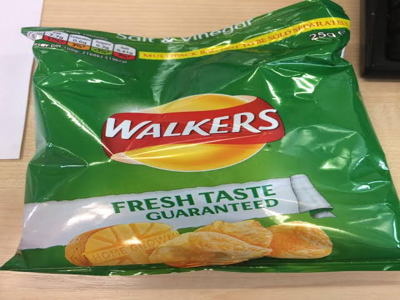

Prediction: trash
Model score: 79.4%


In [87]:
from google.colab import files
from PIL import Image
import io

photo_upload = files.upload()
assert len(photo_upload) == 1, 'Please upload one photo'

photo_name = next(iter(photo_upload))
photo = Image.open(io.BytesIO(photo_upload[photo_name])).convert('RGB')

model.eval()
image_tensor = eval_transform(photo).unsqueeze(0).to(device)

with torch.no_grad():
    probabilities = model(image_tensor).softmax(dim=1)[0]

predicted_index = probabilities.argmax().item()

display(photo.resize((400, 300)))
print('Prediction:', class_names[predicted_index])
print(f'Model score: {probabilities[predicted_index].item():.1%}')

In [88]:
for index in probabilities.argsort(descending=True).tolist():
    print(f'{class_names[index]}: {probabilities[index].item():.1%}')


trash: 79.4%
cardboard: 17.7%
paper: 2.1%
metal: 0.7%
plastic: 0.1%
glass: 0.0%


In [89]:
from sklearn.metrics import accuracy_score, classification_report

model.eval()
updated_actual = []
updated_predicted = []

with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(device)).argmax(dim=1)
        updated_predicted.extend(predictions.cpu().tolist())
        updated_actual.extend(labels.tolist())

print(f"Test accuracy: {accuracy_score(updated_actual, updated_predicted):.1%}")
print(classification_report(
    updated_actual,
    updated_predicted,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=3,
    zero_division=0
))

Test accuracy: 84.3%
              precision    recall  f1-score   support

   cardboard      0.917     0.902     0.909        61
       glass      0.765     0.816     0.790        76
       metal      0.826     0.919     0.870        62
       paper      0.895     0.856     0.875        90
     plastic      0.877     0.781     0.826        73
       trash      0.682     0.714     0.698        21

    accuracy                          0.843       383
   macro avg      0.827     0.831     0.828       383
weighted avg      0.847     0.843     0.844       383



In [90]:
from pathlib import Path
from google.colab import files

report = (
    f"Test accuracy: {accuracy_score(updated_actual, updated_predicted):.1%}\n\n"
    + classification_report(
        updated_actual,
        updated_predicted,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

report_path = Path("/content/EcoSort_Updated_Test_Results.txt")
report_path.write_text(report, encoding="utf-8")
files.download(str(report_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>